<a href="https://colab.research.google.com/github/okana2ki/intro-to-DS/blob/main/SSDSE_C_2026intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[https://www.nstac.go.jp/files/SSDSE-C-2026.csv](https://www.nstac.go.jp/files/SSDSE-C-2026.csv)からデータを読み込む

In [2]:
import pandas as pd

url = 'https://www.nstac.go.jp/files/SSDSE-C-2026.csv'
# サーバーによるブロックを回避するため、User-Agentを指定します
storage_options = {'User-Agent': 'Mozilla/5.0'}
df = pd.read_csv(url, encoding='shift_jis', storage_options=storage_options)
df.head()


,SSDSE-C-2026,2023-2025年,City,LA03,LB00,LB01,LB011001,LB012001,LB012002,LB013001,...,LB121104,LB121105,LB121106,LB121107,LB121108,LB121109,LB121110,LB121201,LB121202,LB122001
0,地域コード,都道府県,市,世帯人員,食料（合計）,01 穀類,米,食パン,他のパン,生うどん・そば,...,すし（外食）,和食,中華食,洋食,焼肉,ハンバーガー,他の主食的外食,喫茶代,飲酒代,学校給食
1,R00000,全国,全国,2.88,1085539,91820,30111,10713,23530,3777,...,16577,26615,5121,13378,8444,6446,54738,10261,18073,7756
2,R01100,北海道,札幌市,2.77,1007628,91994,35984,9366,19957,3515,...,17303,23714,3580,18638,8162,4823,26979,7456,21073,12205
3,R02201,青森県,青森市,2.79,1010524,87921,29339,9621,19671,3387,...,14942,16945,3117,9401,7194,4529,20519,4626,11361,1247
4,R03201,岩手県,盛岡市,2.85,1042728,86816,28660,8716,20144,3730,...,14794,14403,2200,7384,7674,4926,47895,7112,20520,10972


ぎょうざの支出金額が多い順にソートする

In [3]:
# 1行目のデータから「ぎょうざ」の列名を特定
gyoza_col = df.columns[df.iloc[0] == 'ぎょうざ'][0]

# 1行目(項目名)と2行目(全国)を除外してデータ部分を抽出
df_data = df.iloc[2:].copy()

# ぎょうざの支出金額を数値型に変換
df_data[gyoza_col] = pd.to_numeric(df_data[gyoza_col])

# ぎょうざの支出金額が多い順(降順)にソート
df_sorted = df_data.sort_values(by=gyoza_col, ascending=False)

# 都道府県、市、ぎょうざの支出金額の上位10件を表示
df_sorted[['2023-2025年', 'City', gyoza_col]].head(10)


,2023-2025年,City,LB092007
46,宮崎県,宮崎市,3478
10,栃木県,宇都宮市,3192
26,滋賀県,大津市,2455
12,埼玉県,さいたま市,2412
27,京都府,京都市,2314
28,大阪府,大阪市,2261
47,鹿児島県,鹿児島市,2251
24,愛知県,名古屋市,2200
14,東京都,東京都区部,2110
13,千葉県,千葉市,2076


焼酎の支出金額が多い順にソートする

In [4]:
# 1行目のデータから「焼酎」の列名を特定
shochu_col = df.columns[df.iloc[0] == '焼酎'][0]

# 1行目(項目名)と2行目(全国)を除外してデータ部分を抽出
df_data = df.iloc[2:].copy()

# 焼酎の支出金額を数値型に変換
df_data[shochu_col] = pd.to_numeric(df_data[shochu_col])

# 焼酎の支出金額が多い順(降順)にソート
df_sorted_shochu = df_data.sort_values(by=shochu_col, ascending=False)

# 都道府県、市、焼酎の支出金額の上位10件を表示
df_sorted_shochu[['2023-2025年', 'City', shochu_col]].head(10)


,2023-2025年,City,LB110002
46,宮崎県,宮崎市,12067
47,鹿児島県,鹿児島市,11351
45,大分県,大分市,8521
36,山口県,山口市,8054
44,熊本県,熊本市,7844
3,青森県,青森市,7756
48,沖縄県,那覇市,7742
33,島根県,松江市,7468
34,岡山県,岡山市,7455
42,佐賀県,佐賀市,7340


ぎょうざと焼酎の支出金額の相関を散布図で描画してください。
ぎょうざ、焼酎、それぞれ支出金額が上位3番目までの都市名を散布図内に表示して。

In [ ]:
!pip install japanize-matplotlib

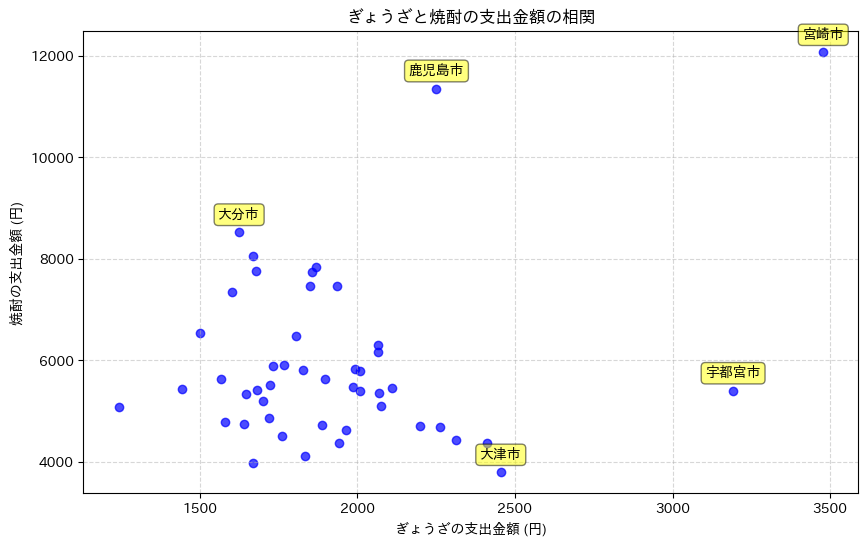

In [8]:
import matplotlib.pyplot as plt
import japanize_matplotlib
import pandas as pd

# ぎょうざと焼酎のデータを数値型に変換
df_data[gyoza_col] = pd.to_numeric(df_data[gyoza_col])
df_data[shochu_col] = pd.to_numeric(df_data[shochu_col])

# 散布図の作成
plt.figure(figsize=(10, 6))
plt.scatter(df_data[gyoza_col], df_data[shochu_col], color='b', alpha=0.7)

# 上位3つの都市を取得してラベル付け
top3_gyoza = df_data.nlargest(3, gyoza_col)
top3_shochu = df_data.nlargest(3, shochu_col)
top_cities = pd.concat([top3_gyoza, top3_shochu]).drop_duplicates(subset=['City'])

for idx, row in top_cities.iterrows():
    plt.annotate(row['City'], (row[gyoza_col], row[shochu_col]),
                 textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10,
                 bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))

# タイトルとラベルの設定
plt.title('ぎょうざと焼酎の支出金額の相関')
plt.xlabel('ぎょうざの支出金額 (円)')
plt.ylabel('焼酎の支出金額 (円)')

# グリッドの表示
plt.grid(True, linestyle='--', alpha=0.5)

# グラフの表示
plt.show()
